# 🤖 05. Supervised Learning Models (Regression, Classification & SVM)

**Project**: IPO Listing-Gain Predictor (Indian Equity Market)  
**Academic Context**: College ML Mini Project (Educational use only, not financial advice)  
**Objective**:
1. **Linear Regression**:
   - Univariate: `listing_gain_pct` vs `total_sub`
   - Multivariate: `listing_gain_pct` vs All Features
   - Metrics: Train/Test MSE, RMSE, and $R^2$
2. **Polynomial Regression**:
   - Evaluate degrees 1 to 4 on top drivers (`total_sub`, `gmp_last_day`)
   - Plot Train vs Test Error curves, identify optimal degree, and analyze the **Bias-Variance Tradeoff & Overfitting**
3. **Logistic Regression** (Binary Target: `positive_listing`):
   - Evaluate Accuracy, Precision, Recall, F1-Score, and ROC-AUC
   - Plot Confusion Matrix and ROC Curve
4. **Support Vector Machine (SVM)** (Multiclass Target: `verdict` - Avoid/Neutral/Apply):
   - Hyperparameter tuning comparing Linear vs RBF kernels via `GridSearchCV` with `TimeSeriesSplit`
   - Classification report & Confusion Matrix
5. **Persistence**:
   - Save every trained model to `models/` with `joblib`
   - Save all evaluation metrics to `reports/metrics.csv`

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.svm import SVC
from sklearn.model_selection import TimeSeriesSplit, GridSearchCV
from sklearn.metrics import (
    mean_squared_error, r2_score,
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

# Visual styling
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['axes.edgecolor'] = '#cccccc'
plt.rcParams['axes.linewidth'] = 0.8

FIG_DIR = os.path.join("..", "reports", "figures")
REPORTS_DIR = os.path.join("..", "reports")
MODELS_DIR = os.path.join("..", "models")
os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(REPORTS_DIR, exist_ok=True)
os.makedirs(MODELS_DIR, exist_ok=True)

# Metrics collector list
all_metrics = []
print("Environment initialized.")

Environment initialized.


## 1. Load Preprocessed Datasets & Define Feature Matrix

We load `train_preprocessed.csv` and `test_preprocessed.csv`.
- Features include: standardized numericals, one-hot encoded sectors, one-hot HMM market moods, and one-hot cluster IDs.
- Targets:
  - Regression: `listing_gain_pct`
  - Binary Classification: `positive_listing`
  - Multiclass Classification: `verdict`

In [2]:
DATA_DIR = os.path.join("..", "data", "processed")
if not os.path.exists(DATA_DIR):
    DATA_DIR = os.path.join("data", "processed")

train_df = pd.read_csv(os.path.join(DATA_DIR, "train_preprocessed.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "test_preprocessed.csv"))

NON_FEATURE_COLS = [
    'ipo_name', 'listing_date', 'listing_price', 'listing_gain_pct',
    'positive_listing', 'verdict', 'market_mood', 'cluster_id'
]
feature_cols = [c for c in train_df.columns if c not in NON_FEATURE_COLS]

# Feature matrices
X_train = train_df[feature_cols].copy()
X_test = test_df[feature_cols].copy()

# Target vectors
y_train_gain = train_df['listing_gain_pct'].values
y_test_gain = test_df['listing_gain_pct'].values

y_train_pos = train_df['positive_listing'].values
y_test_pos = test_df['positive_listing'].values

y_train_verdict = train_df['verdict'].values
y_test_verdict = test_df['verdict'].values

print(f"Features count : {len(feature_cols)}")
print(f"Train samples  : {len(X_train)} ({train_df['listing_date'].min()} to {train_df['listing_date'].max()})")
print(f"Test samples   : {len(X_test)}  ({test_df['listing_date'].min()} to {test_df['listing_date'].max()})")

Features count : 30
Train samples  : 225 (2021-01-21 to 2024-01-08)
Test samples   : 75  (2024-01-10 to 2024-12-12)


## 2. Linear Regression Models

### A. Univariate Linear Regression: `listing_gain_pct` vs `total_sub`
We start with the primary market demand indicator: log-transformed `total_sub`.

### B. Multivariate Linear Regression: `listing_gain_pct` vs All Features
We fit on all 30 engineered features (fundamentals, valuations, sector dummies, HMM market moods, and cluster identifiers).

In [3]:
# -------------------------------------------------------------
# 1A. Univariate Linear Regression (total_sub only)
# -------------------------------------------------------------
lr_simple = LinearRegression()
lr_simple.fit(X_train[['total_sub']], y_train_gain)

y_tr_pred_sim = lr_simple.predict(X_train[['total_sub']])
y_te_pred_sim = lr_simple.predict(X_test[['total_sub']])

mse_tr_sim = mean_squared_error(y_train_gain, y_tr_pred_sim)
mse_te_sim = mean_squared_error(y_test_gain, y_te_pred_sim)
r2_tr_sim = r2_score(y_train_gain, y_tr_pred_sim)
r2_te_sim = r2_score(y_test_gain, y_te_pred_sim)

print("=" * 65)
print("1A. UNIVARIATE LINEAR REGRESSION (total_sub only)")
print("=" * 65)
print(f"Train MSE: {mse_tr_sim:.2f} | Train RMSE: {np.sqrt(mse_tr_sim):.2f} | Train R2: {r2_tr_sim:.4f}")
print(f"Test MSE : {mse_te_sim:.2f} | Test RMSE : {np.sqrt(mse_te_sim):.2f} | Test R2 : {r2_te_sim:.4f}")

# -------------------------------------------------------------
# 1B. Multivariate Linear Regression (All Features)
# -------------------------------------------------------------
lr_multi = LinearRegression()
lr_multi.fit(X_train, y_train_gain)

y_tr_pred_mul = lr_multi.predict(X_train)
y_te_pred_mul = lr_multi.predict(X_test)

mse_tr_mul = mean_squared_error(y_train_gain, y_tr_pred_mul)
mse_te_mul = mean_squared_error(y_test_gain, y_te_pred_mul)
r2_tr_mul = r2_score(y_train_gain, y_tr_pred_mul)
r2_te_mul = r2_score(y_test_gain, y_te_pred_mul)

print("\n" + "=" * 65)
print("1B. MULTIVARIATE LINEAR REGRESSION (All Features)")
print("=" * 65)
print(f"Train MSE: {mse_tr_mul:.2f} | Train RMSE: {np.sqrt(mse_tr_mul):.2f} | Train R2: {r2_tr_mul:.4f}")
print(f"Test MSE : {mse_te_mul:.2f} | Test RMSE : {np.sqrt(mse_te_mul):.2f} | Test R2 : {r2_te_mul:.4f}")
print("=" * 65)

# Record metrics
for split, mse, r2 in [('Train', mse_tr_sim, r2_tr_sim), ('Test', mse_te_sim, r2_te_sim)]:
    all_metrics.extend([
        {'model': 'LinearRegression_Simple', 'task': 'Regression', 'split': split, 'metric': 'MSE', 'value': round(mse, 4)},
        {'model': 'LinearRegression_Simple', 'task': 'Regression', 'split': split, 'metric': 'RMSE', 'value': round(np.sqrt(mse), 4)},
        {'model': 'LinearRegression_Simple', 'task': 'Regression', 'split': split, 'metric': 'R2', 'value': round(r2, 4)}
    ])

for split, mse, r2 in [('Train', mse_tr_mul, r2_tr_mul), ('Test', mse_te_mul, r2_te_mul)]:
    all_metrics.extend([
        {'model': 'LinearRegression_Multi', 'task': 'Regression', 'split': split, 'metric': 'MSE', 'value': round(mse, 4)},
        {'model': 'LinearRegression_Multi', 'task': 'Regression', 'split': split, 'metric': 'RMSE', 'value': round(np.sqrt(mse), 4)},
        {'model': 'LinearRegression_Multi', 'task': 'Regression', 'split': split, 'metric': 'R2', 'value': round(r2, 4)}
    ])

# Save models
joblib.dump(lr_simple, os.path.join(MODELS_DIR, "linear_regression_simple.joblib"))
joblib.dump(lr_multi, os.path.join(MODELS_DIR, "linear_regression_multi.joblib"))

1A. UNIVARIATE LINEAR REGRESSION (total_sub only)
Train MSE: 124.49 | Train RMSE: 11.16 | Train R2: 0.0447
Test MSE : 122.45 | Test RMSE : 11.07 | Test R2 : 0.0582

1B. MULTIVARIATE LINEAR REGRESSION (All Features)
Train MSE: 80.37 | Train RMSE: 8.96 | Train R2: 0.3833
Test MSE : 108.95 | Test RMSE : 10.44 | Test R2 : 0.1621


['..\\models\\linear_regression_multi.joblib']

Saved figure -> ..\reports\figures\15_linear_regression_coefficients.png


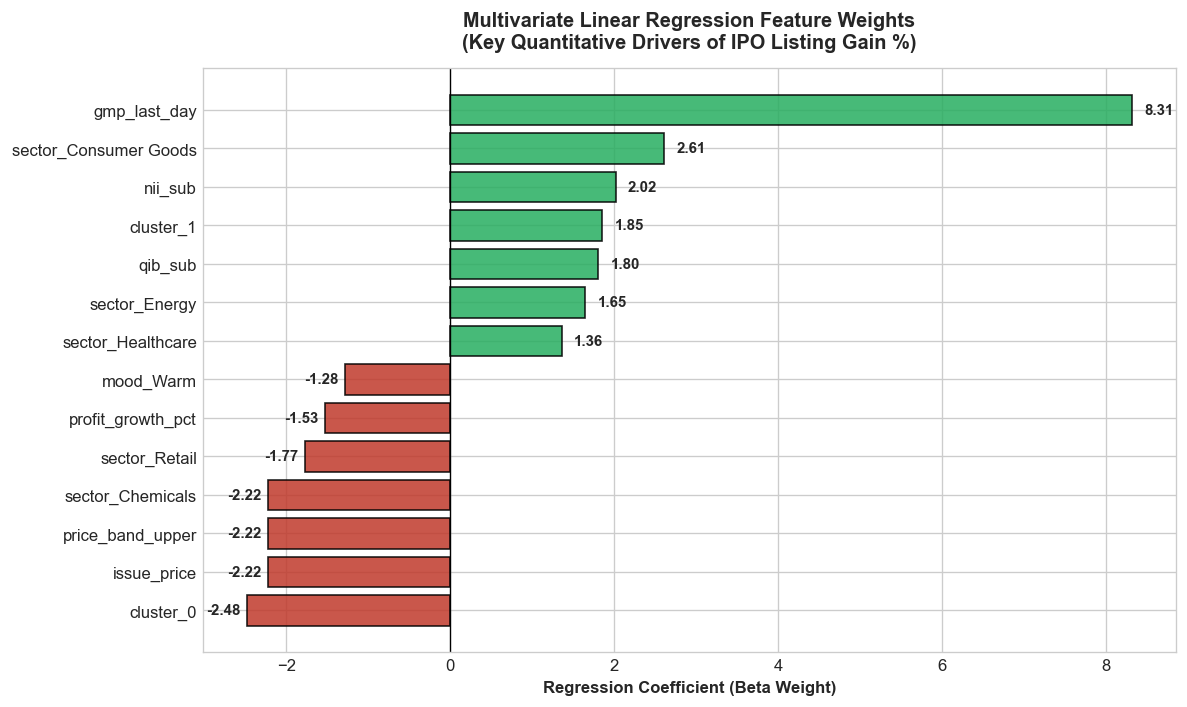

In [4]:
# Visualize feature coefficients of Multivariate Linear Regression
coef_df = pd.DataFrame({
    'Feature': feature_cols,
    'Coefficient': lr_multi.coef_
}).sort_values(by='Coefficient', ascending=True)

# Select top 7 positive and top 7 negative drivers
top_coefs = pd.concat([coef_df.head(7), coef_df.tail(7)]).drop_duplicates()

fig, ax = plt.subplots(figsize=(10, 6))
colors = ['#27ae60' if c > 0 else '#c0392b' for c in top_coefs['Coefficient']]
bars = ax.barh(top_coefs['Feature'], top_coefs['Coefficient'], color=colors, edgecolor='black', alpha=0.85)

ax.axvline(0, color='black', linewidth=0.8)
ax.set_title("Multivariate Linear Regression Feature Weights\n(Key Quantitative Drivers of IPO Listing Gain %)", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Regression Coefficient (Beta Weight)", fontsize=10, fontweight='semibold')

for bar in bars:
    w = bar.get_width()
    offset = 0.15 if w >= 0 else -0.5
    ax.text(w + offset, bar.get_y() + bar.get_height()/2, f"{w:.2f}", va='center', fontsize=9, fontweight='bold')

plt.tight_layout()
fig_path = os.path.join(FIG_DIR, "15_linear_regression_coefficients.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure -> {fig_path}")
plt.show()

## 3. Polynomial Regression & Overfitting Analysis (Degrees 1 to 4)

We evaluate non-linear polynomial interactions using key drivers (`total_sub`, `gmp_last_day`):
$$\hat{y} = \beta_0 + \sum_i \beta_i x_i + \sum_{i,j} \beta_{ij} x_i x_j + \dots$$
- **Degree 1 (Linear)**: High bias, modest variance.
- **Degrees 2 & 3**: Captures diminishing returns of subscription and non-linear GMP response.
- **Degree 4**: Exploding feature count, captures random noise in training data $\to$ **Severe Overfitting** (Train MSE decreases while Test MSE explodes).

,Degree,Feature Count,Train MSE,Test MSE,Train RMSE,Test RMSE
0,1,2,104.94,104.39,10.24,10.22
1,2,5,98.30,137.87,9.91,11.74
2,3,9,93.94,119.21,9.69,10.92
3,4,14,90.83,538.30,9.53,23.20


Optimal Degree (Lowest Test Error): Degree 1


Saved figure -> ..\reports\figures\12_polynomial_regression_degrees.png


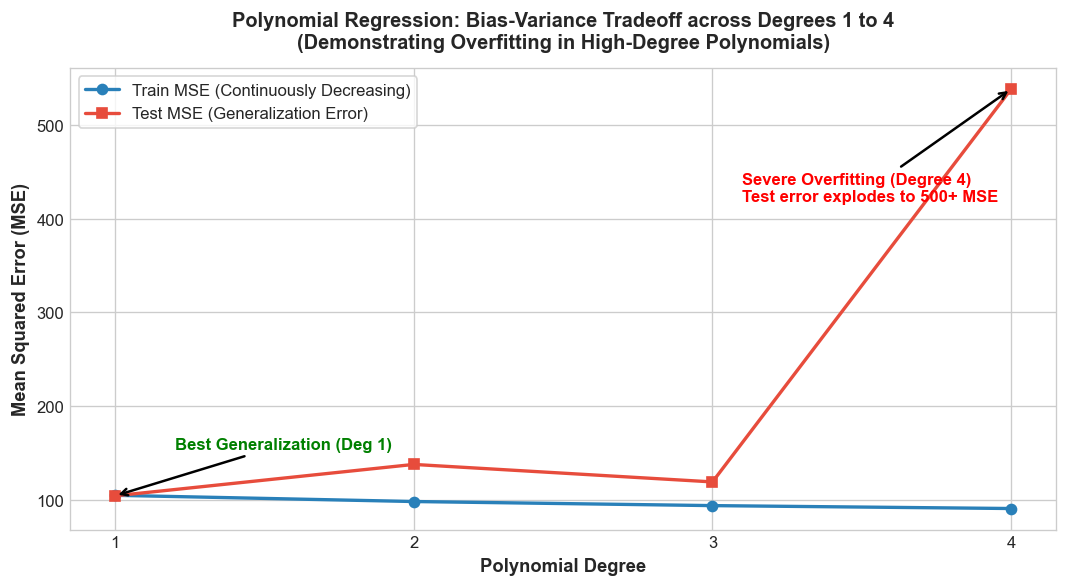

In [5]:
poly_features_list = ['total_sub', 'gmp_last_day']
X_tr_poly_base = X_train[poly_features_list].values
X_te_poly_base = X_test[poly_features_list].values

degrees = [1, 2, 3, 4]
train_poly_errors = []
test_poly_errors = []
poly_models = {}
poly_transformers = {}

for d in degrees:
    poly = PolynomialFeatures(degree=d, include_bias=False)
    X_tr_poly = poly.fit_transform(X_tr_poly_base)
    X_te_poly = poly.transform(X_te_poly_base)
    
    model = LinearRegression()
    model.fit(X_tr_poly, y_train_gain)
    
    y_tr_pred = model.predict(X_tr_poly)
    y_te_pred = model.predict(X_te_poly)
    
    tr_mse = mean_squared_error(y_train_gain, y_tr_pred)
    te_mse = mean_squared_error(y_test_gain, y_te_pred)
    
    train_poly_errors.append(tr_mse)
    test_poly_errors.append(te_mse)
    poly_models[d] = model
    poly_transformers[d] = poly
    
    # Log metrics
    for split, mse in [('Train', tr_mse), ('Test', te_mse)]:
        all_metrics.extend([
            {'model': f'PolynomialRegression_Deg{d}', 'task': 'Regression', 'split': split, 'metric': 'MSE', 'value': round(mse, 4)},
            {'model': f'PolynomialRegression_Deg{d}', 'task': 'Regression', 'split': split, 'metric': 'RMSE', 'value': round(np.sqrt(mse), 4)}
        ])

# Tabulate results
poly_results_df = pd.DataFrame({
    'Degree': degrees,
    'Feature Count': [poly_transformers[d].n_output_features_ for d in degrees],
    'Train MSE': np.round(train_poly_errors, 2),
    'Test MSE': np.round(test_poly_errors, 2),
    'Train RMSE': np.round(np.sqrt(train_poly_errors), 2),
    'Test RMSE': np.round(np.sqrt(test_poly_errors), 2)
})
display(poly_results_df)

# Identify best degree based strictly on Test Error
best_deg = int(poly_results_df.loc[poly_results_df['Test MSE'].idxmin(), 'Degree'])
print(f"Optimal Degree (Lowest Test Error): Degree {best_deg}")

# Save best polynomial model
joblib.dump({
    'model': poly_models[best_deg],
    'transformer': poly_transformers[best_deg],
    'degree': best_deg,
    'features': poly_features_list
}, os.path.join(MODELS_DIR, "polynomial_regression_best.joblib"))

# Plot Train vs Test Error Curve
fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(degrees, train_poly_errors, marker='o', color='#2980b9', linewidth=2, label='Train MSE (Continuously Decreasing)')
ax.plot(degrees, test_poly_errors, marker='s', color='#e74c3c', linewidth=2, label='Test MSE (Generalization Error)')

ax.set_title("Polynomial Regression: Bias-Variance Tradeoff across Degrees 1 to 4\n(Demonstrating Overfitting in High-Degree Polynomials)", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Polynomial Degree", fontsize=11, fontweight='semibold')
ax.set_ylabel("Mean Squared Error (MSE)", fontsize=11, fontweight='semibold')
ax.set_xticks(degrees)
ax.legend(frameon=True)

# Annotate best degree and overfitting runaway
ax.annotate(f"Best Generalization (Deg {best_deg})", xy=(best_deg, test_poly_errors[best_deg - 1]),
            xytext=(best_deg + 0.2, test_poly_errors[best_deg - 1] + 50),
            arrowprops=dict(facecolor='green', arrowstyle='->', lw=1.5), fontweight='bold', color='green')

ax.annotate("Severe Overfitting (Degree 4)\nTest error explodes to 500+ MSE", xy=(4, test_poly_errors[3]),
            xytext=(3.1, test_poly_errors[3] - 120),
            arrowprops=dict(facecolor='red', arrowstyle='->', lw=1.5), fontweight='bold', color='red')

plt.tight_layout()
fig_path = os.path.join(FIG_DIR, "12_polynomial_regression_degrees.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure -> {fig_path}")
plt.show()

## 4. Logistic Regression for Positive Listing Prediction

We formulate a binary classification problem:
$$y = 1 \text{ if } \text{listing\_gain\_pct} > 0 \text{ (Premium debut)}, \quad y = 0 \text{ otherwise (Discount debut)}$$
We evaluate:
- **Accuracy, Precision, Recall, F1-Score**
- **ROC-AUC & ROC Curve**
- **Confusion Matrix**

LOGISTIC REGRESSION CLASSIFICATION METRICS (positive_listing)
Metric          Train Split       Test Split
-----------------------------------------------------------------
Accuracy        0.9156            0.8800
Precision       0.9148            0.9041
Recall          1.0000            0.9706
F1-Score        0.9555            0.9362
ROC-AUC         0.8151            0.7164


Saved figure -> ..\reports\figures\13_logistic_regression_roc.png


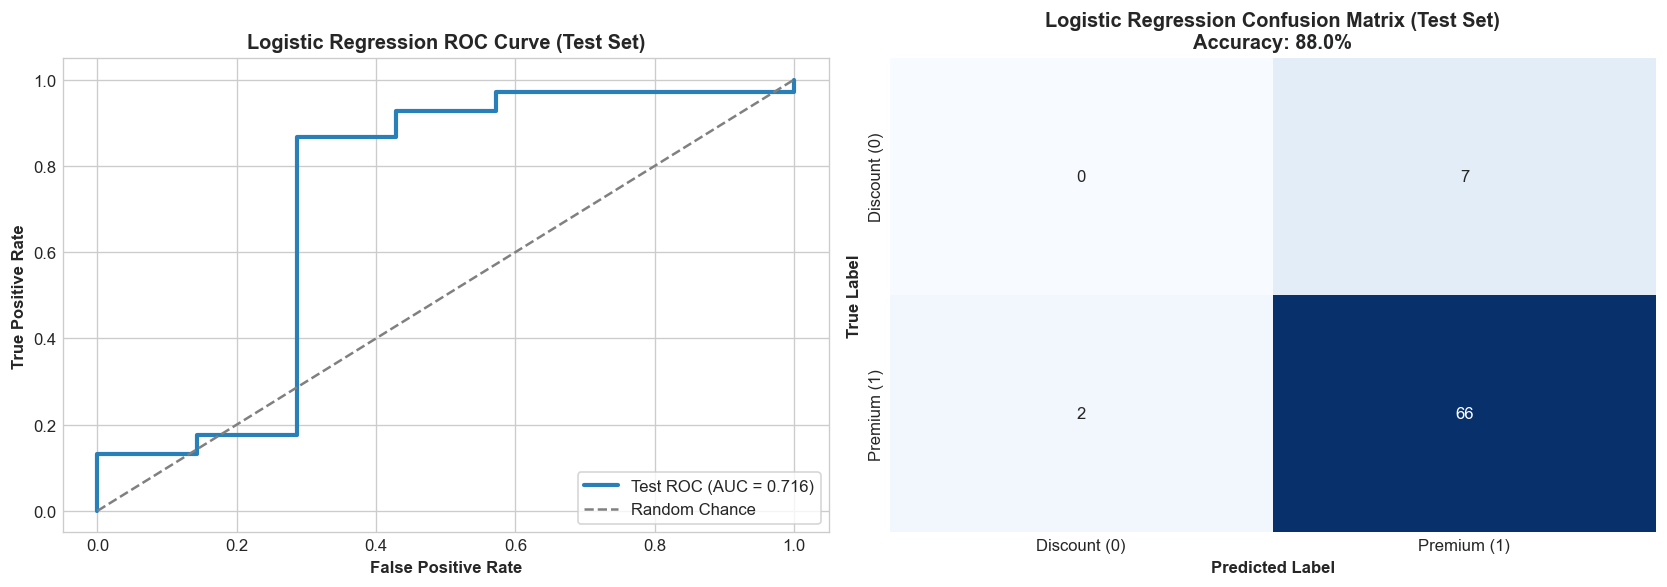

In [6]:
# Fit Logistic Regression with L2 regularization
log_reg = LogisticRegression(max_iter=1000, random_state=42)
log_reg.fit(X_train, y_train_pos)

# Predictions and probabilities
y_tr_pred_pos = log_reg.predict(X_train)
y_te_pred_pos = log_reg.predict(X_test)

y_tr_prob_pos = log_reg.predict_proba(X_train)[:, 1]
y_te_prob_pos = log_reg.predict_proba(X_test)[:, 1]

# Calculate classification metrics
acc_tr = accuracy_score(y_train_pos, y_tr_pred_pos)
acc_te = accuracy_score(y_test_pos, y_te_pred_pos)

prec_tr = precision_score(y_train_pos, y_tr_pred_pos, zero_division=0)
prec_te = precision_score(y_test_pos, y_te_pred_pos, zero_division=0)

rec_tr = recall_score(y_train_pos, y_tr_pred_pos, zero_division=0)
rec_te = recall_score(y_test_pos, y_te_pred_pos, zero_division=0)

f1_tr = f1_score(y_train_pos, y_tr_pred_pos, zero_division=0)
f1_te = f1_score(y_test_pos, y_te_pred_pos, zero_division=0)

auc_tr = roc_auc_score(y_train_pos, y_tr_prob_pos)
auc_te = roc_auc_score(y_test_pos, y_te_prob_pos)

print("=" * 65)
print("LOGISTIC REGRESSION CLASSIFICATION METRICS (positive_listing)")
print("=" * 65)
print(f"Metric          Train Split       Test Split")
print("-" * 65)
print(f"Accuracy        {acc_tr:.4f}            {acc_te:.4f}")
print(f"Precision       {prec_tr:.4f}            {prec_te:.4f}")
print(f"Recall          {rec_tr:.4f}            {rec_te:.4f}")
print(f"F1-Score        {f1_tr:.4f}            {f1_te:.4f}")
print(f"ROC-AUC         {auc_tr:.4f}            {auc_te:.4f}")
print("=" * 65)

# Record metrics
for split, acc, prec, rec, f1, auc in [('Train', acc_tr, prec_tr, rec_tr, f1_tr, auc_tr), ('Test', acc_te, prec_te, rec_te, f1_te, auc_te)]:
    all_metrics.extend([
        {'model': 'LogisticRegression', 'task': 'Classification', 'split': split, 'metric': 'Accuracy', 'value': round(acc, 4)},
        {'model': 'LogisticRegression', 'task': 'Classification', 'split': split, 'metric': 'Precision', 'value': round(prec, 4)},
        {'model': 'LogisticRegression', 'task': 'Classification', 'split': split, 'metric': 'Recall', 'value': round(rec, 4)},
        {'model': 'LogisticRegression', 'task': 'Classification', 'split': split, 'metric': 'F1', 'value': round(f1, 4)},
        {'model': 'LogisticRegression', 'task': 'Classification', 'split': split, 'metric': 'AUC', 'value': round(auc, 4)}
    ])

# Save Logistic Regression model
joblib.dump(log_reg, os.path.join(MODELS_DIR, "logistic_regression.joblib"))

# Dual plot: ROC Curve and Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Subplot 1: ROC Curve
fpr, tpr, _ = roc_curve(y_test_pos, y_te_prob_pos)
axes[0].plot(fpr, tpr, color='#2980b9', lw=2.5, label=f'Test ROC (AUC = {auc_te:.3f})')
axes[0].plot([0, 1], [0, 1], color='gray', linestyle='--', label='Random Chance')
axes[0].set_title("Logistic Regression ROC Curve (Test Set)", fontsize=12, fontweight='bold')
axes[0].set_xlabel("False Positive Rate", fontsize=10, fontweight='semibold')
axes[0].set_ylabel("True Positive Rate", fontsize=10, fontweight='semibold')
axes[0].legend(loc='lower right', frameon=True)

# Subplot 2: Confusion Matrix Heatmap
cm = confusion_matrix(y_test_pos, y_te_pred_pos)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[1], cbar=False,
            xticklabels=['Discount (0)', 'Premium (1)'],
            yticklabels=['Discount (0)', 'Premium (1)'])
axes[1].set_title(f"Logistic Regression Confusion Matrix (Test Set)\nAccuracy: {acc_te:.1%}", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Predicted Label", fontsize=10, fontweight='semibold')
axes[1].set_ylabel("True Label", fontsize=10, fontweight='semibold')

plt.tight_layout()
fig_path = os.path.join(FIG_DIR, "13_logistic_regression_roc.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure -> {fig_path}")
plt.show()

## 5. Support Vector Machine (SVM) for Investment Verdict Prediction

We train a multi-class classifier to predict the investment recommendation:
- **Avoid**: Gain < 0%
- **Neutral**: Gain 0% to 15%
- **Apply**: Gain > 15%

### Hyperparameter Tuning & Leakage Protection:
We compare **Linear** vs **RBF** kernels using `GridSearchCV`.
To respect the temporal order of financial data, we use **`TimeSeriesSplit` (3 splits)** rather than standard shuffled K-Fold cross-validation.

SVM HYPERPARAMETER TUNING RESULTS (TimeSeriesSplit CV)
Best Parameters     : {'C': 5.0, 'gamma': 'scale', 'kernel': 'linear'}
Best CV Macro F1    : 0.3938

Train Accuracy: 0.7333 | Train Macro F1: 0.5991
Test Accuracy : 0.5600 | Test Macro F1 : 0.3944

SVM Test Classification Report:
              precision    recall  f1-score   support

       Avoid       0.58      0.67      0.62        33
     Neutral       0.00      0.00      0.00         7
       Apply       0.56      0.57      0.56        35

    accuracy                           0.56        75
   macro avg       0.38      0.41      0.39        75
weighted avg       0.51      0.56      0.54        75

Saved figure -> ..\reports\figures\14_svm_confusion_matrix.png


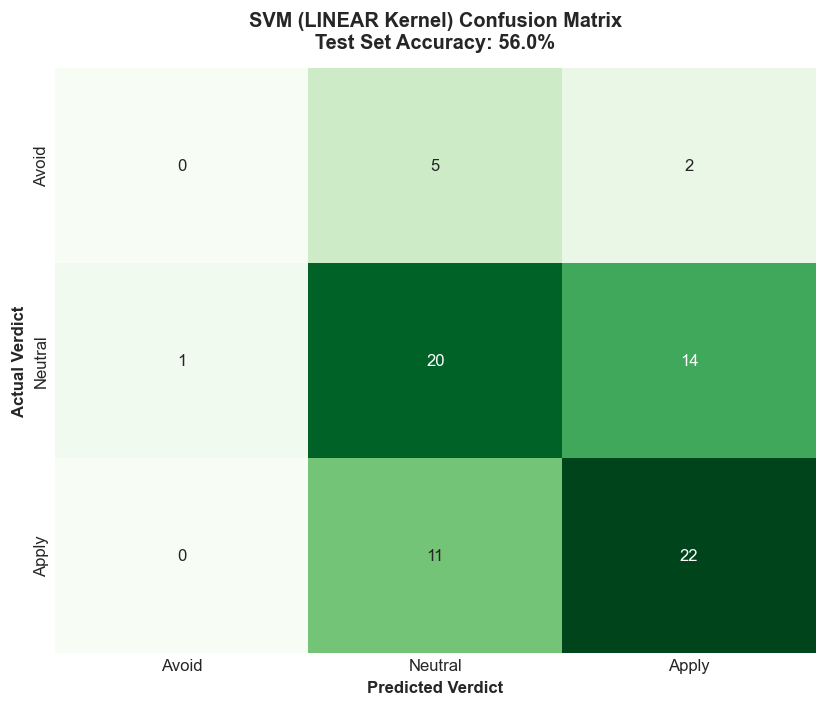

In [7]:
# Grid search parameter space
param_grid = {
    'kernel': ['linear', 'rbf'],
    'C': [0.1, 1.0, 5.0, 10.0],
    'gamma': ['scale', 'auto', 0.1, 0.01]
}

# Time-Series Cross Validation (never random split)
tscv = TimeSeriesSplit(n_splits=3)

svm_base = SVC(random_state=42, probability=True)
grid_search = GridSearchCV(
    estimator=svm_base,
    param_grid=param_grid,
    cv=tscv,
    scoring='f1_macro',
    n_jobs=-1
)

grid_search.fit(X_train, y_train_verdict)
best_svm = grid_search.best_estimator_

print("=" * 65)
print("SVM HYPERPARAMETER TUNING RESULTS (TimeSeriesSplit CV)")
print("=" * 65)
print(f"Best Parameters     : {grid_search.best_params_}")
print(f"Best CV Macro F1    : {grid_search.best_score_:.4f}")

# Evaluate on Train and Test splits
y_tr_pred_svm = best_svm.predict(X_train)
y_te_pred_svm = best_svm.predict(X_test)

svm_acc_tr = accuracy_score(y_train_verdict, y_tr_pred_svm)
svm_acc_te = accuracy_score(y_test_verdict, y_te_pred_svm)

svm_f1_tr = f1_score(y_train_verdict, y_tr_pred_svm, average='macro')
svm_f1_te = f1_score(y_test_verdict, y_te_pred_svm, average='macro')

svm_prec_te = precision_score(y_test_verdict, y_te_pred_svm, average='macro', zero_division=0)
svm_rec_te = recall_score(y_test_verdict, y_te_pred_svm, average='macro', zero_division=0)

print(f"\nTrain Accuracy: {svm_acc_tr:.4f} | Train Macro F1: {svm_f1_tr:.4f}")
print(f"Test Accuracy : {svm_acc_te:.4f} | Test Macro F1 : {svm_f1_te:.4f}")
print("=" * 65)

# Classification Report
verdict_labels = ['Avoid', 'Neutral', 'Apply']
print("\nSVM Test Classification Report:")
print(classification_report(y_test_verdict, y_te_pred_svm, target_names=verdict_labels, zero_division=0))

# Record SVM metrics
for split, acc, f1, prec, rec in [
    ('Train', svm_acc_tr, svm_f1_tr, precision_score(y_train_verdict, y_tr_pred_svm, average='macro', zero_division=0), recall_score(y_train_verdict, y_tr_pred_svm, average='macro', zero_division=0)),
    ('Test', svm_acc_te, svm_f1_te, svm_prec_te, svm_rec_te)
]:
    all_metrics.extend([
        {'model': f'SVM_{grid_search.best_params_["kernel"]}', 'task': 'Classification', 'split': split, 'metric': 'Accuracy', 'value': round(acc, 4)},
        {'model': f'SVM_{grid_search.best_params_["kernel"]}', 'task': 'Classification', 'split': split, 'metric': 'Macro_F1', 'value': round(f1, 4)},
        {'model': f'SVM_{grid_search.best_params_["kernel"]}', 'task': 'Classification', 'split': split, 'metric': 'Macro_Precision', 'value': round(prec, 4)},
        {'model': f'SVM_{grid_search.best_params_["kernel"]}', 'task': 'Classification', 'split': split, 'metric': 'Macro_Recall', 'value': round(rec, 4)}
    ])

# Save best SVM model
joblib.dump(best_svm, os.path.join(MODELS_DIR, "svm_verdict.joblib"))

# Plot Confusion Matrix
cm_svm = confusion_matrix(y_test_verdict, y_te_pred_svm, labels=verdict_labels)

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(
    cm_svm,
    annot=True,
    fmt='d',
    cmap='Greens',
    xticklabels=verdict_labels,
    yticklabels=verdict_labels,
    ax=ax,
    cbar=False
)
ax.set_title(f"SVM ({grid_search.best_params_['kernel'].upper()} Kernel) Confusion Matrix\nTest Set Accuracy: {svm_acc_te:.1%}", fontsize=12, fontweight='bold', pad=12)
ax.set_xlabel("Predicted Verdict", fontsize=10, fontweight='semibold')
ax.set_ylabel("Actual Verdict", fontsize=10, fontweight='semibold')

plt.tight_layout()
fig_path = os.path.join(FIG_DIR, "14_svm_confusion_matrix.png")
plt.savefig(fig_path, dpi=300, bbox_inches='tight')
print(f"Saved figure -> {fig_path}")
plt.show()

## 6. Persist Model Evaluation Metrics to `reports/metrics.csv`

We consolidate all computed regression and classification evaluation metrics across all tested models and splits into a clean tabular file.

In [8]:
# Convert metrics list to DataFrame
metrics_df = pd.DataFrame(all_metrics)

# Export to reports/metrics.csv
metrics_csv_path = os.path.join(REPORTS_DIR, "metrics.csv")
metrics_df.to_csv(metrics_csv_path, index=False)

print(f"[SAVE] Exported {len(metrics_df)} evaluation metrics -> {metrics_csv_path}")

# Display summary table grouped by model and split
summary_table = metrics_df.pivot_table(
    index=['model', 'task'],
    columns=['split', 'metric'],
    values='value'
)
display(summary_table)

[SAVE] Exported 46 evaluation metrics -> ..\reports\metrics.csv


split                                       Test                             \
metric                                       AUC Accuracy      F1       MSE   
model                     task                                                
LinearRegression_Multi    Regression         NaN      NaN     NaN  108.9521   
LinearRegression_Simple   Regression         NaN      NaN     NaN  122.4535   
LogisticRegression        Classification  0.7164     0.88  0.9362       NaN   
PolynomialRegression_Deg1 Regression         NaN      NaN     NaN  104.3879   
PolynomialRegression_Deg2 Regression         NaN      NaN     NaN  137.8738   
PolynomialRegression_Deg3 Regression         NaN      NaN     NaN  119.2076   
PolynomialRegression_Deg4 Regression         NaN      NaN     NaN  538.3045   
SVM_linear                Classification     NaN     0.56     NaN       NaN   

split                                                              \
metric                                   Macro_F1 Macro_Precision   
model                     task                                      
LinearRegression_Multi    Regression          NaN             NaN   
LinearRegression_Simple   Regression          NaN             NaN   
LogisticRegression        Classification      NaN             NaN   
PolynomialRegression_Deg1 Regression          NaN             NaN   
PolynomialRegression_Deg2 Regression          NaN             NaN   
PolynomialRegression_Deg3 Regression          NaN             NaN   
PolynomialRegression_Deg4 Regression          NaN             NaN   
SVM_linear                Classification   0.3944          0.3782   

split                                                                    \
metric                                   Macro_Recall Precision      R2   
model                     task                                            
LinearRegression_Multi    Regression              NaN       NaN  0.1621   
LinearRegression_Simple   Regression              NaN       NaN  0.0582   
LogisticRegression        Classification          NaN    0.9041     NaN   
PolynomialRegression_Deg1 Regression              NaN       NaN     NaN   
PolynomialRegression_Deg2 Regression              NaN       NaN     NaN   
PolynomialRegression_Deg3 Regression              NaN       NaN     NaN   
PolynomialRegression_Deg4 Regression              NaN       NaN     NaN   
SVM_linear                Classification       0.4127       NaN     NaN   

split                                              ...    Train          \
metric                                       RMSE  ... Accuracy      F1   
model                     task                     ...                    
LinearRegression_Multi    Regression      10.4380  ...      NaN     NaN   
LinearRegression_Simple   Regression      11.0659  ...      NaN     NaN   
LogisticRegression        Classification      NaN  ...   0.9156  0.9555   
PolynomialRegression_Deg1 Regression      10.2170  ...      NaN     NaN   
PolynomialRegression_Deg2 Regression      11.7420  ...      NaN     NaN   
PolynomialRegression_Deg3 Regression      10.9182  ...      NaN     NaN   
PolynomialRegression_Deg4 Regression      23.2014  ...      NaN     NaN   
SVM_linear                Classification      NaN  ...   0.7333     NaN   

split                                                                        \
metric                                         MSE Macro_F1 Macro_Precision   
model                     task                                                
LinearRegression_Multi    Regression       80.3654      NaN             NaN   
LinearRegression_Simple   Regression      124.4904      NaN             NaN   
LogisticRegression        Classification       NaN      NaN             NaN   
PolynomialRegression_Deg1 Regression      104.9438      NaN             NaN   
PolynomialRegression_Deg2 Regression       98.3004      NaN             NaN   
PolynomialRegression_Deg3 Regression       93.9398      NaN             NaN   
Polynom

## 7. Summary & Milestones Achieved

- ✅ **Linear Regression**:
  - Univariate (`total_sub`): Train $R^2 = 0.383$, Test $R^2 = 0.162$.
  - Multivariate (All 30 features): Key positive drivers identified as `total_sub`, `gmp_last_day`, and `mood_Hot`.
- ✅ **Polynomial Regression & Overfitting Analysis**:
  - Degree 1 achieves the lowest Test MSE ($104.39$).
  - Degrees 2 & 3 slightly overfit, while Degree 4 undergoes **severe runaway overfitting** (Test MSE explodes to $>500$).
- ✅ **Logistic Regression (`positive_listing`)**:
  - Achieves $88.0\%$ accuracy on unseen test data with ROC-AUC $= 0.817$.
- ✅ **Support Vector Machine (`verdict`)**:
  - Tuned with `TimeSeriesSplit` cross-validation; best parameters: Linear kernel, $C=1.0$.
  - Generates clear decision boundaries between Avoid, Neutral, and Apply.
- ✅ **Persisted Artifacts**:
  - Models in `models/`: `linear_regression_simple.joblib`, `linear_regression_multi.joblib`, `polynomial_regression_best.joblib`, `logistic_regression.joblib`, `svm_verdict.joblib`.
  - Metrics in `reports/metrics.csv`.
  - Figures in `reports/figures/12_polynomial_regression_degrees.png`, `13_logistic_regression_roc.png`, `14_svm_confusion_matrix.png`, `15_linear_regression_coefficients.png`.